# Adapter 전문가 없는 단일 모델 · 개선 및 ADBench 평가

알고리즘별 탐지기 하나. IF·K-means·LOF 사이의 별도 앙상블도 없다. 기존 원본·평가 CSV·정답은 유지했다. 아래의 기존 로그 시나리오와 ADBench 숫자 피처 평가를 구분해서 읽는다.

In [1]:
from pathlib import Path
import json,pandas as pd
from IPython.display import display,Image,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/adbench_1000/manifest.json').exists())
OUT=ROOT/'reports/shared_model_v2_release'
read=lambda p:json.loads(p.read_text(encoding='utf-8'))
result=read(OUT/'summary.json'); selected=read(OUT/'selection.json'); old=read(ROOT/'reports/shared_model_target_lof/summary.json')
def metrics(rows):
    return (pd.DataFrame(rows).set_index('method')[[c for c in ['accuracy','precision','recall','f1','normal_false_positive_rate','average_precision','roc_auc'] if c in pd.DataFrame(rows)]]*100).round(2)

## 1. 전체 결과

기존 **6개 시나리오 + Hard 전체 2,167,766개 1분 판정**. 정상 1,785,918개, 이상 381,848개. 정상 오탐률은 FP/(TN+FP). 정상 대조군뿐 아니라 이상 사례 속 정상 배경 분도 포함한다. 항상 정상이라고 해도 Accuracy는 82.39%이므로 F1·Recall을 함께 본다.

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,87.46,74.70,43.53,55.01,3.15,57.89,74.38
kmeans,88.17,80.72,43.13,56.22,2.20,60.83,78.11
lof,87.85,79.01,42.25,55.06,2.40,58.85,75.63


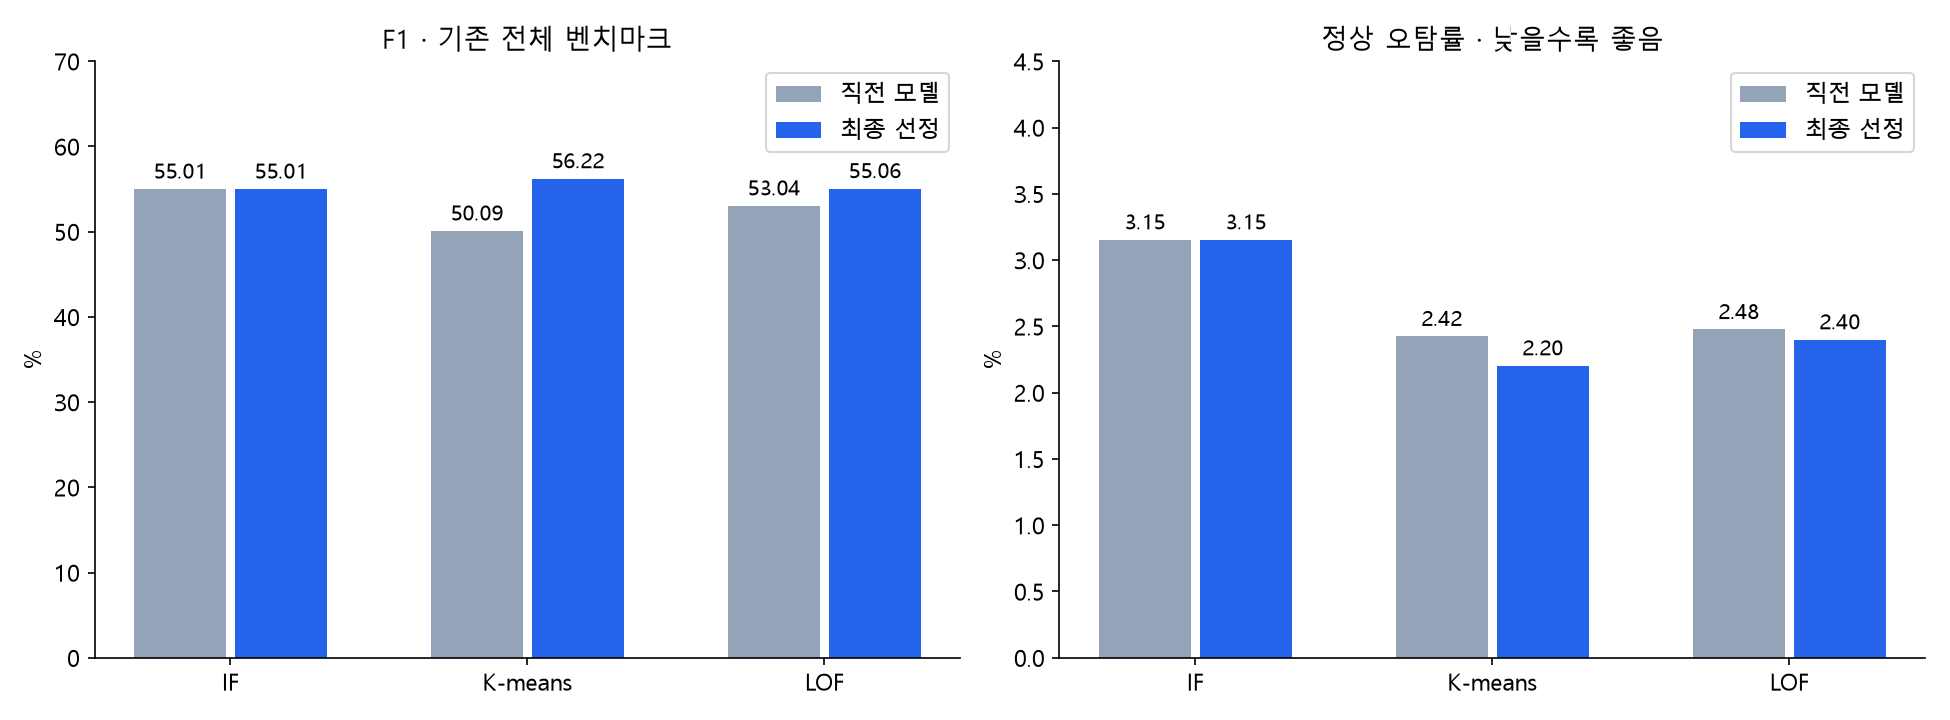

,method,F1_before,F1_after,F1_delta_pp,FPR_before,FPR_after
0,if,0.550062,0.550062,0.000000,0.031532,0.031532
1,kmeans,0.500926,0.562231,6.130582,0.024245,0.022029
2,lof,0.530375,0.550573,2.019799,0.024765,0.023992


In [2]:
display(metrics(result['pooled']))
display(Image(filename=str(OUT/'figures/comparison.png')))
display(pd.DataFrame(read(OUT/'comparisons.json')))

## 2. 무엇을 바꿨고 왜 효과가 있었나

- **K-means**: 정상 S 학습 자료에도 드문 큰 변동이 있다. 안정화된 피처 공간에서 큰 거리 상위 1%를 **중심 적합에서만** 제외하는 후보를 비교하고 8개 군집을 선택했다. 실제 로그/평가 정답을 삭제한 것이 아니고, 정상 경보선 산정에는 정상 calibration 전체를 사용했다. 완전한 Trimmed k-means 구현은 아니다.
- 현재 소요시간, 초기 관측 대비 지연, 증가 추세가 함께 높아지는 정도 등 **6개 관계 피처** 추가. 단순히 값 하나만 큰 경우와 여러 근거가 맞는 경우를 구분할 수 있게 했다.
- 최근 완료에서 확인한 지연을 최대 3/8분까지 감쇠시키는 **9개 기억·트래픽 피처**도 비교. 새 정상 완료가 오면 바로 갱신되며 미래 완료를 읽지 않는다. 선택된 모델의 실제 입력 수는 아래 설정 표 참조.
- **LOF**: 이웃 수·참고 표본 수·Adapter 피처 가중치·정상 점수 보정과 인과적인 점수 완화 후보를 비교했다. 채택 여부와 정확한 값은 manifest 표에 표시한다.
- **IF**: 새 후보가 기존 전체 F1을 넘지 못해 기존 55.01% 모델을 유지했다. 모든 모델이 개선됐다고 주장하지 않는다.
- PCA, 공분산 안정화, 거리 변경, 중복 빈도 보존/잡음 평활 등도 비교했지만 최종 선택과 구분한다. 하이퍼파라미터와 경보선도 달라졌으므로 순수 Adapter 피처 추가 효과만의 비교는 아니다.

In [3]:
manifest=read(OUT/'handoff/manifest.json')
for r in manifest['models']:
    a=r['algorithm']; s=r['settings']
    relevant={'if':['trees','samples','whitening','rotation'],'kmeans':['clusters','geometry','trim','interactions'],'lof':['neighbors','reference_cap','metric','interactions','deduplicate','projection']}[a]
    v={k:s[k] for k in ['adapter_weight','memory_weight','memory',*relevant] if k in s}
    v.update({'total_features':len(r['columns']),'Adapter_features':r['adapter_feature_count'],'fit_or_reference_rows':r['fit_rows'],'normal_quantile':selected['selected'][a]['q'],'threshold':r['threshold'],'score_calibration':r['calibration_mode']+' / '+r['calibration_kind'],'detector_count':r['estimator_count']})
    display(Markdown('### '+a));display(pd.Series(v,name='설정').to_frame())
    if 'causal_score_filter' in r: display(pd.Series(r['causal_score_filter'],name='과거 점수 처리').to_frame())
    display(pd.DataFrame({'actual_model_features':r['columns']}))

### if

,설정
adapter_weight,0.25
trees,300
samples,256
whitening,True
rotation,True
total_features,26
Adapter_features,9
fit_or_reference_rows,19793
normal_quantile,0.98
threshold,3.759943


,actual_model_features
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_delay
6,current_source_upper
7,current_source_lower
8,current_prefix_delay
9,current_recent_delay


### kmeans

,설정
adapter_weight,0.25
memory_weight,0.5
memory,True
clusters,8
geometry,radius
trim,0.01
interactions,True
total_features,41
Adapter_features,9
fit_or_reference_rows,19595


,actual_model_features
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_delay
6,current_source_upper
7,current_source_lower
8,current_prefix_delay
9,current_recent_delay


### lof

,설정
adapter_weight,0.55
memory_weight,0.5
memory,False
neighbors,400
reference_cap,2048
metric,euclidean
interactions,True
deduplicate,True
projection,0
total_features,32


,actual_model_features
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_delay
6,current_source_upper
7,current_source_lower
8,current_prefix_delay
9,current_recent_delay


## 3. 피처를 쉬운 말로 읽기

- **처리건수**는 Process 실행 한 건의 `totalCount`. 분당 요청 수와 다르다.
- **실행 횟수**는 현재 Adapter+Process 스트림의 시간창별 실행 집계.
- `adapter_count_p95_z`: 현재 완료 1분 P95 소요시간을 같은 Adapter·최근 5분 평균 totalCount 구간의 정상 중앙값/IQR과 비교. 정확히 동일한 처리건수만 비교하는 것은 아니다.
- `current_prefix_delay`: 현재 소요시간 잔차가 먼저 관측한 최대 8개 완료 분의 기준보다 얼마나 커졌는지. 초반이 정상이라는 보장은 없다.
- `current_delay_trend`: 직전 최대 15분과 현재까지 확인한 완료 로그의 양수 증가 기울기. 미래 t+k 로그는 읽지 않는다.
- `last_*_3m/8m`: 마지막 완료에서 확인한 근거를 짧게 감쇠해 기억. 0초 정상 로그를 꾸며 넣는 것이 아니다.
- `coherent_*`: 지연·꼬리·추세·실행량 사이의 동시 변화. 새로운 확정 이상 하드 룰이 아니라 숫자 파생 피처다.

모델은 하나여도 Adapter별 정상 참고 통계표는 여러 개이다. 참고가 부족하면 Adapter 단독 → 전체로 확장한다. Process 스트림 집계를 Adapter 정상 분포와 비교한 것이며 Adapter 전체 여러 Process 동시 장애의 실증은 아니다.

## 4. 어떤 시나리오가 좋아지고 나빠졌나

왼쪽은 최종 F1, 오른쪽은 직전 대비 변화다. **음수도 그대로 표시**한다. 전체 F1 상승이나 전체 오탐률 유지가 모든 시나리오의 동시 개선을 뜻하지 않는다.

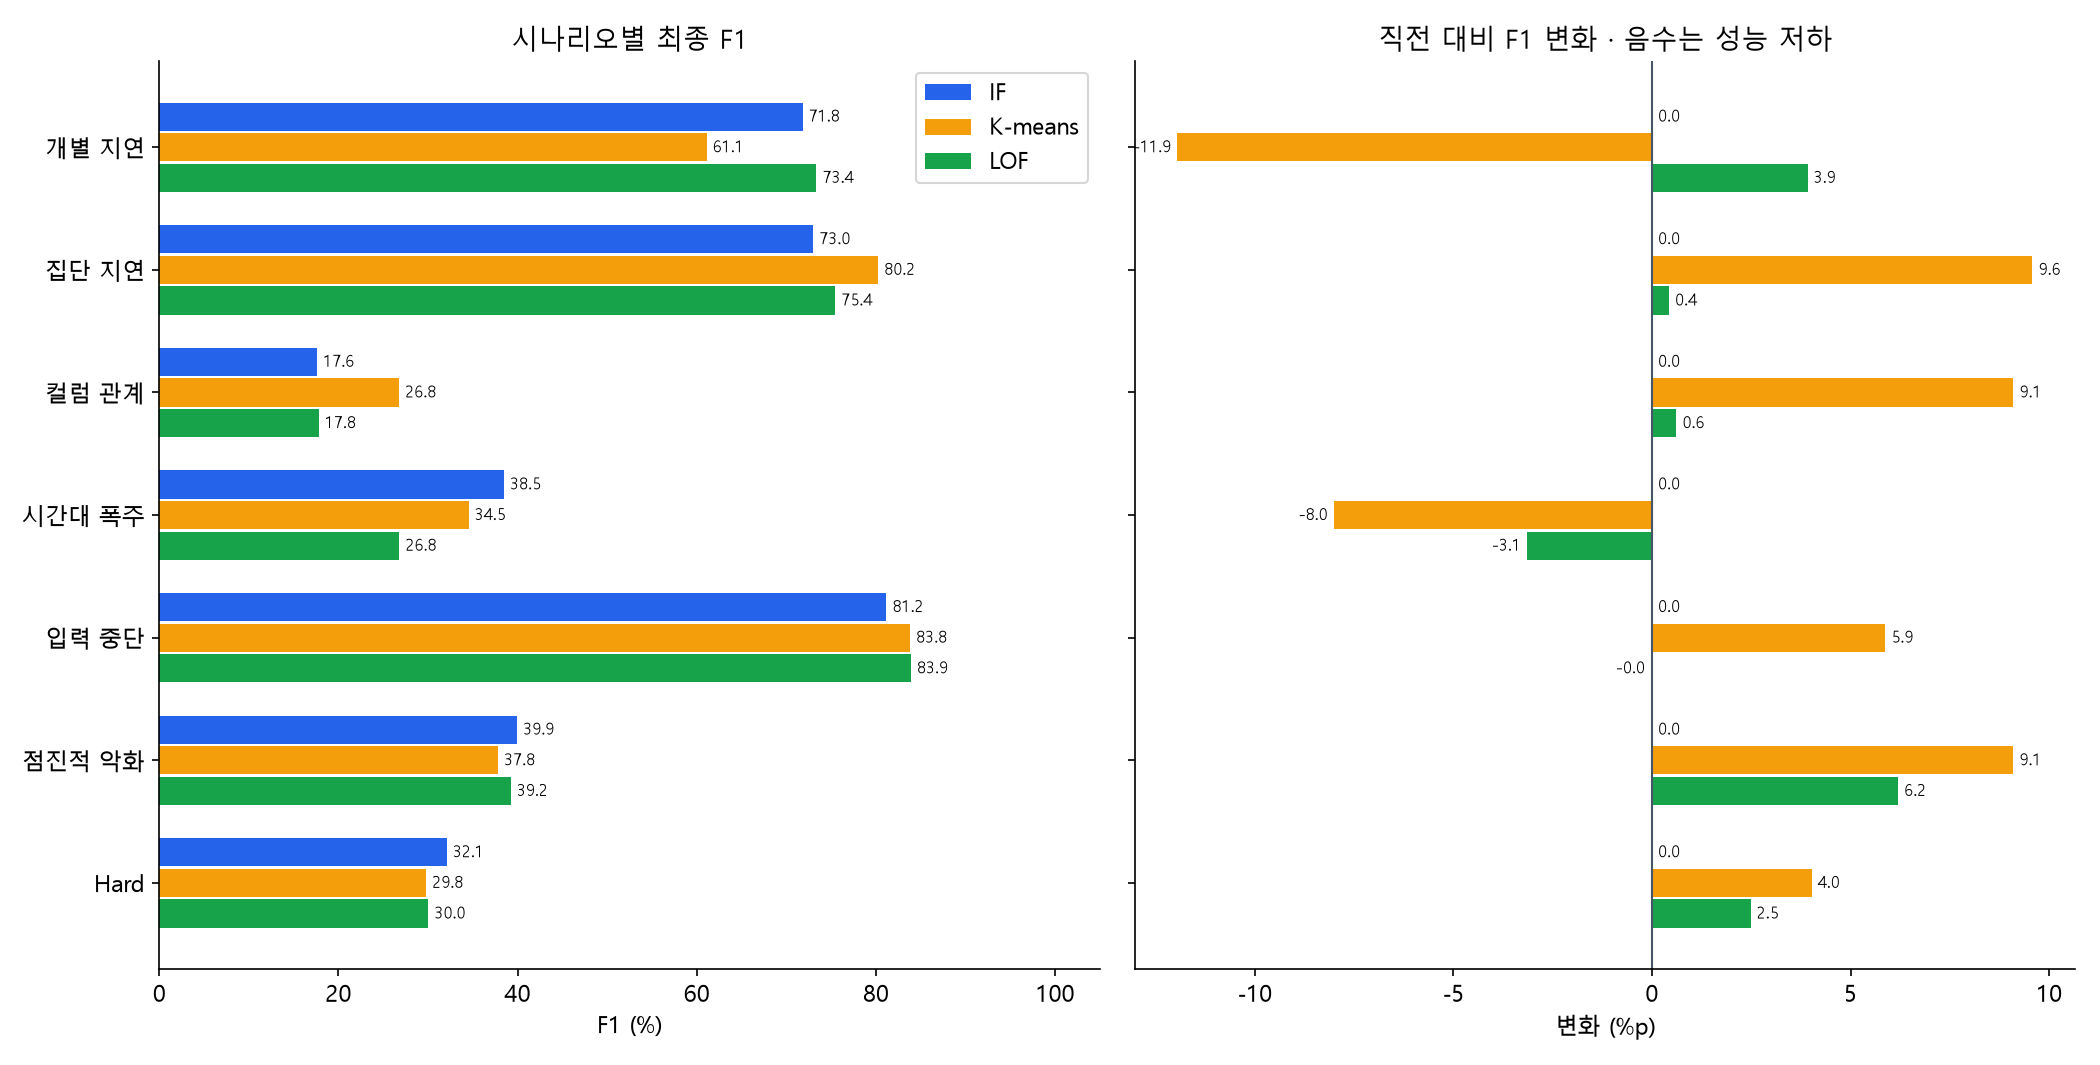

### individual_delay

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,96.08,92.02,58.88,71.82,0.47,76.87,91.99
kmeans,94.00,67.89,55.55,61.10,2.44,53.04,76.77
lof,96.33,95.62,59.51,73.36,0.25,82.23,89.35


### group_delay

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,91.76,72.45,73.55,73.00,4.99,77.28,81.90
kmeans,93.98,79.78,80.72,80.25,3.65,90.09,96.27
lof,92.73,77.22,73.75,75.45,3.88,78.68,84.98


### column_relation

...

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,94.62,91.61,72.88,81.18,1.26,84.55,93.24
kmeans,95.39,95.05,74.94,83.81,0.74,85.99,93.56
lof,95.38,94.11,75.69,83.90,0.90,86.41,94.47


### gradual_degradation

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,78.21,63.56,29.12,39.94,5.53,46.41,62.40
kmeans,78.66,68.74,26.08,37.81,3.93,48.85,66.75
lof,78.70,67.64,27.63,39.23,4.38,47.90,64.00


### mixed_hard

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,79.56,61.51,21.70,32.09,3.89,41.14,58.07
kmeans,80.75,79.03,18.35,29.79,1.39,42.85,61.81
lof,80.28,71.27,19.02,30.03,2.19,41.79,59.15


In [4]:
display(Image(filename=str(OUT/'figures/scenarios.png')))
for d in result['datasets']:
    display(Markdown('### '+d['dataset']));display(metrics(d['metrics']))

## 5. 실제 점수 분포와 경보선

일반 막대 히스토그램. 정상/이상 각각의 전수 분모로 비중을 계산했다. **점선보다 큰 점수**가 경보이다. 표시 밖 꼬리 비중은 제목에 표시하지만 평가에서 제외하지 않았다. 모델별 보정 방식이 달라 점수/threshold 크기를 서로 직접 비교하면 안 된다. 점수는 확률이 아니며 정상 점수 P99가 운영 오탐률 1%를 보장하지 않는다.

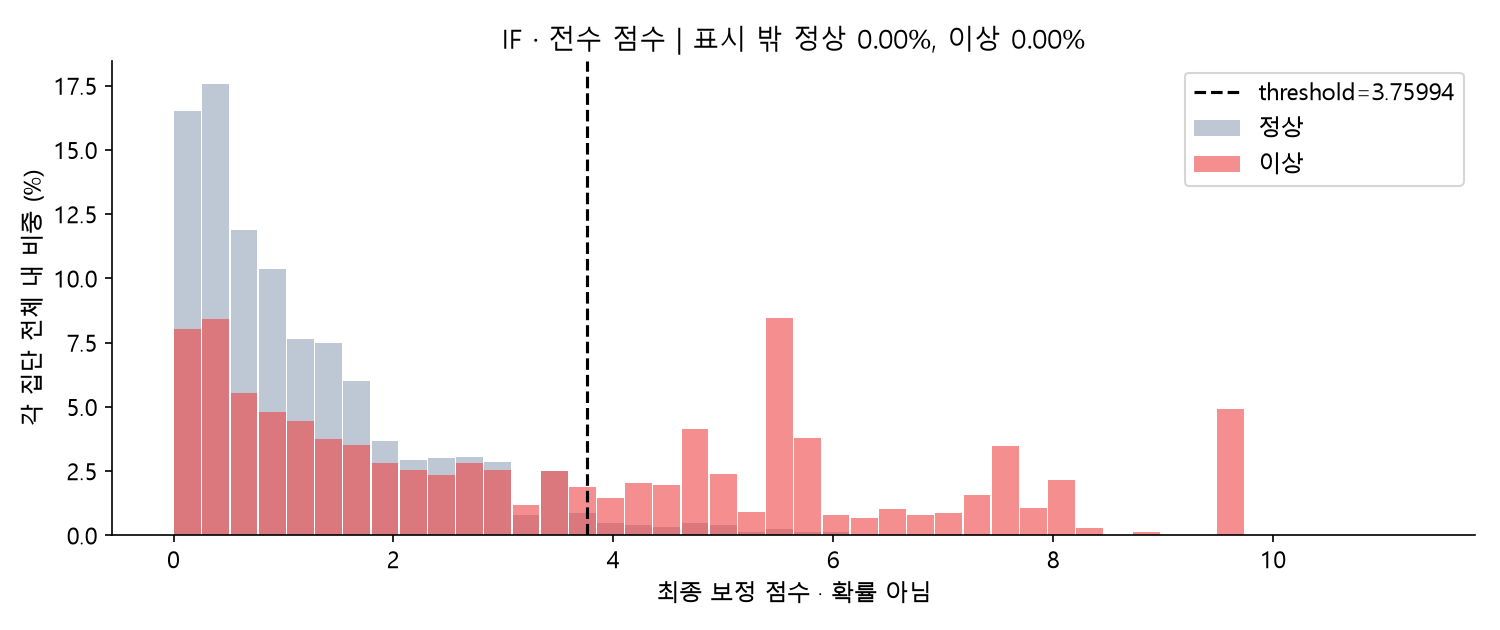

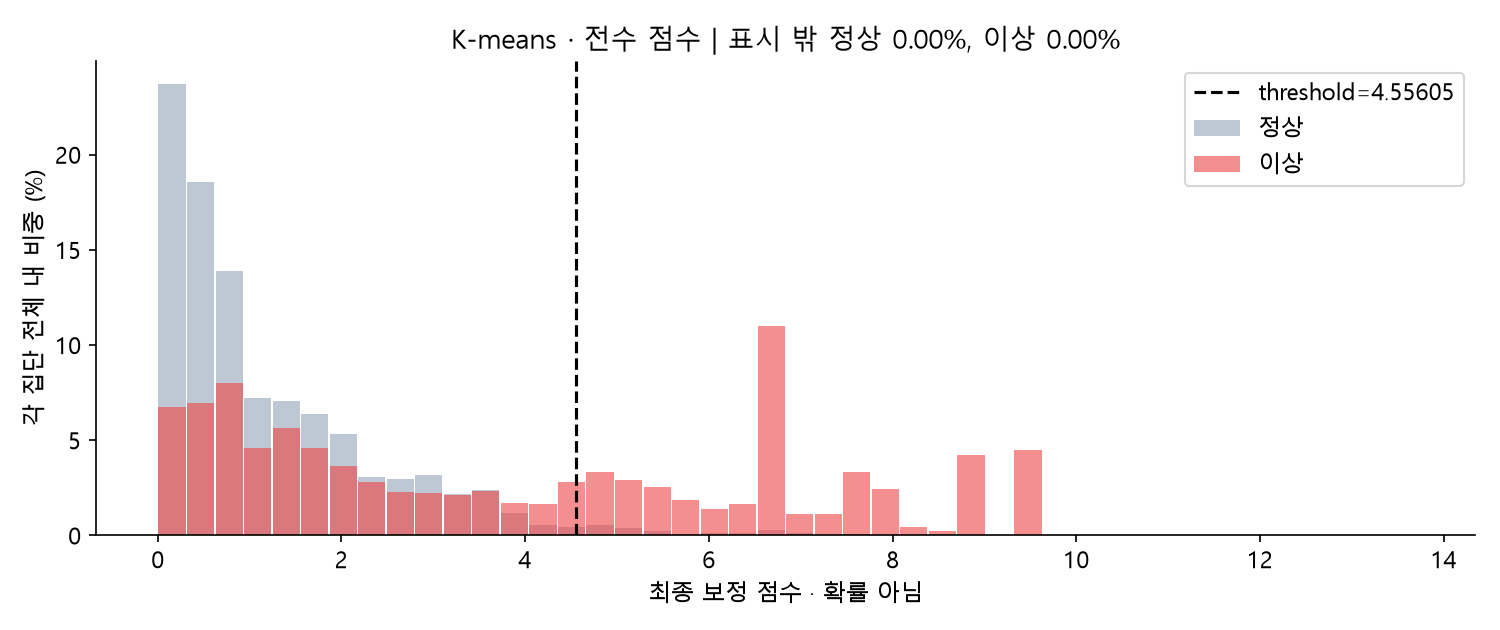

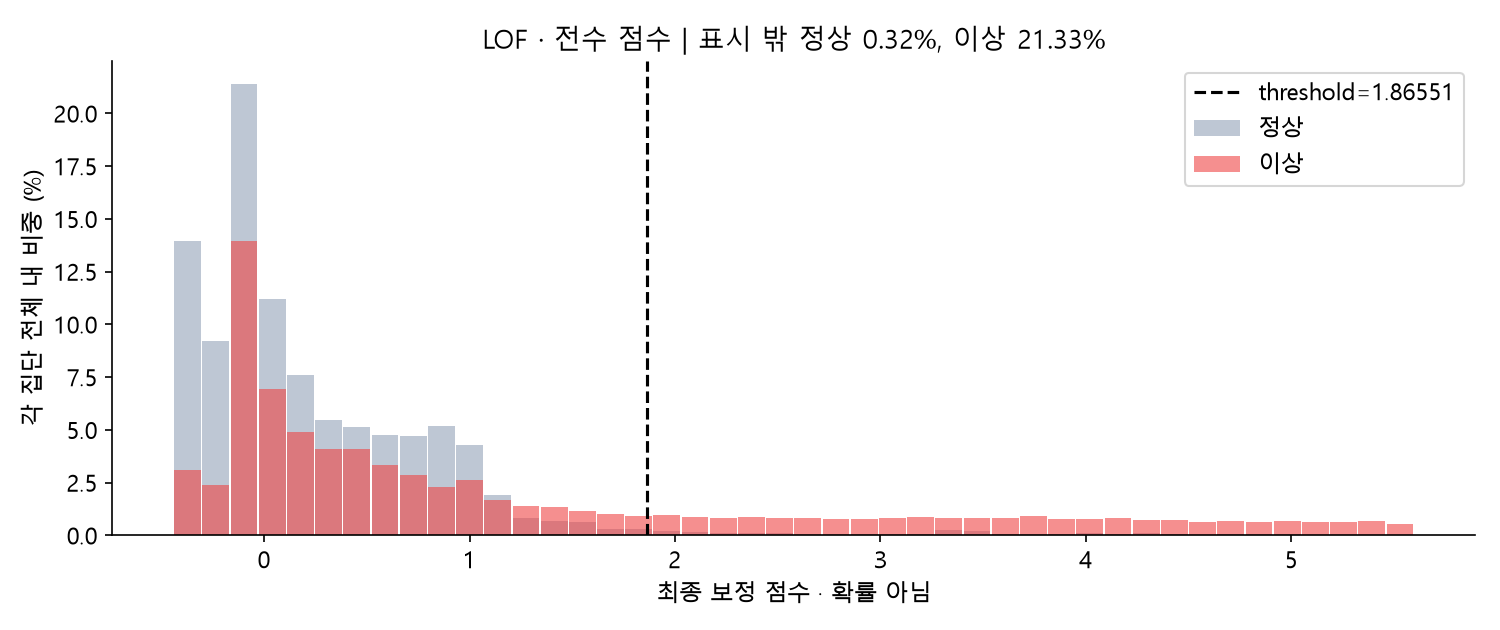

In [5]:
for a in ['if','kmeans','lof']: display(Image(filename=str(OUT/'figures'/f'{a}_threshold.png')))

## 6. 학습·선택·확인을 구분

탐지기와 스케일/Adapter 기준은 정상 train **19,793분**, 점수 기준은 정상 calibration **17,925분**으로 만들었다. K-means 중심 적합 행 수는 1% 제외 후 값이다. 기존 두 개발 분할 **35,782 / 71,618분**에서 파라미터와 경보선을 비교했다. 모델 학습은 정상 후보만의 비지도지만 **설정 선택에는 개발 정답 라벨을 사용했다**.

기존 벤치마크 결과를 보며 구조를 여러 번 개선하고 IF 유지 여부도 판단했다. 따라서 이 벤치마크는 외부 블라인드 테스트가 아니다. 정상/개발/확인 case_id는 분리하되 원본 pool·생성기를 공유하므로 실제 운영 일반화 증거로 과장하지 않는다. 모든 기간의 원본 전 행을 직접 학습한 것도 아니다.

In [6]:
fresh=read(OUT/'fresh_confirmation_v2.json')
display(Markdown('### 최종 모델 동결 후 새 seed 확인 · 재선택에 사용하지 않음'))
display(metrics(fresh['pooled']))
display(Markdown('seed='+str(fresh['seed'])+' / 시나리오당 이상 120사례+정상 120대조 / 같은 원본 생성기, 외부 블라인드 평가 아님'))

### 최종 모델 동결 후 새 seed 확인 · 재선택에 사용하지 않음

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,88.08,67.93,48.95,56.89,4.43
kmeans,89.42,75.63,50.44,60.52,3.11
lof,89.00,74.32,48.24,58.51,3.19


seed=42400042 / 시나리오당 이상 120사례+정상 120대조 / 같은 원본 생성기, 외부 블라인드 평가 아님

## 7. ADBench 1,000개를 실제로 만들고 테스트

정상 **800개 + 이상 200개**. 네 생성 유형별 정상 200개/이상 50개, 총 250개이다. 피처와 정답 CSV를 분리하고 ID/숫자값이 NPZ와 정확히 일치하는지 검증했다. 정답은 모델 입력이 아니라 평가 지표 계산에만 사용한다.

**adbench 0.1.11 공식 `generate_realistic_synthetic` 메서드 본문을 수정 없이 호출**했다. 불필요한 DL import를 피하기 위해 해당 메서드만 로드했으며 pandas 3/copulas의 읽기 전용 배열은 동일 값의 쓰기 가능 복사로 호환 처리했다.

- global: 넓어진 수치 범위의 독립 표본
- local: 정상 GMM 공분산 3배
- cluster: 정상 GMM 평균 3배
- dependency: 정상 피처 관계를 끊고 각 열의 KDE에서 독립 표본

모델 정상 train의 준비/관측 플래그가 모두 True인 자료 1,600개를 생성기 참고로 사용했다. 상수 열/플래그는 유지했고, 나머지 연속 열은 정상 표준화 후 생성·역변환했다. 완성한 1,000개로 모델이나 threshold를 다시 학습하지 않았다.

### previous

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,83.9,73.49,30.5,43.11,2.75,62.49,83.12
kmeans,82.7,78.72,18.5,29.96,1.25,49.65,67.36
lof,84.6,96.00,24.0,38.40,0.25,61.72,80.48


### improved

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,83.9,73.49,30.5,43.11,2.75,62.49,83.12
kmeans,84.0,88.46,23.0,36.51,0.75,65.22,86.53
lof,84.2,82.81,26.5,40.15,1.38,57.52,77.68


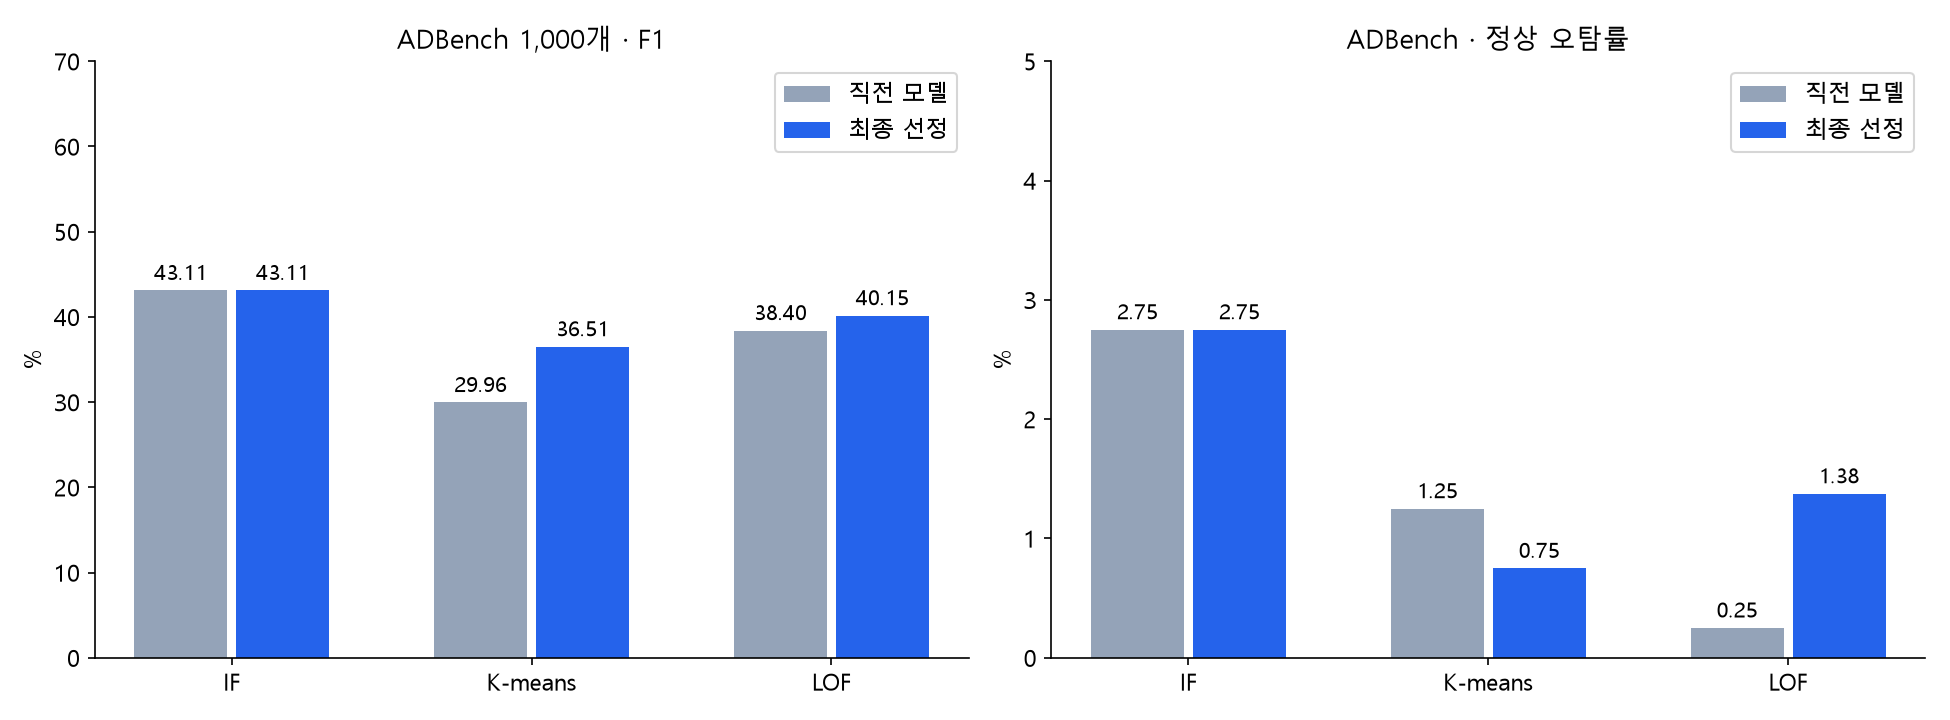

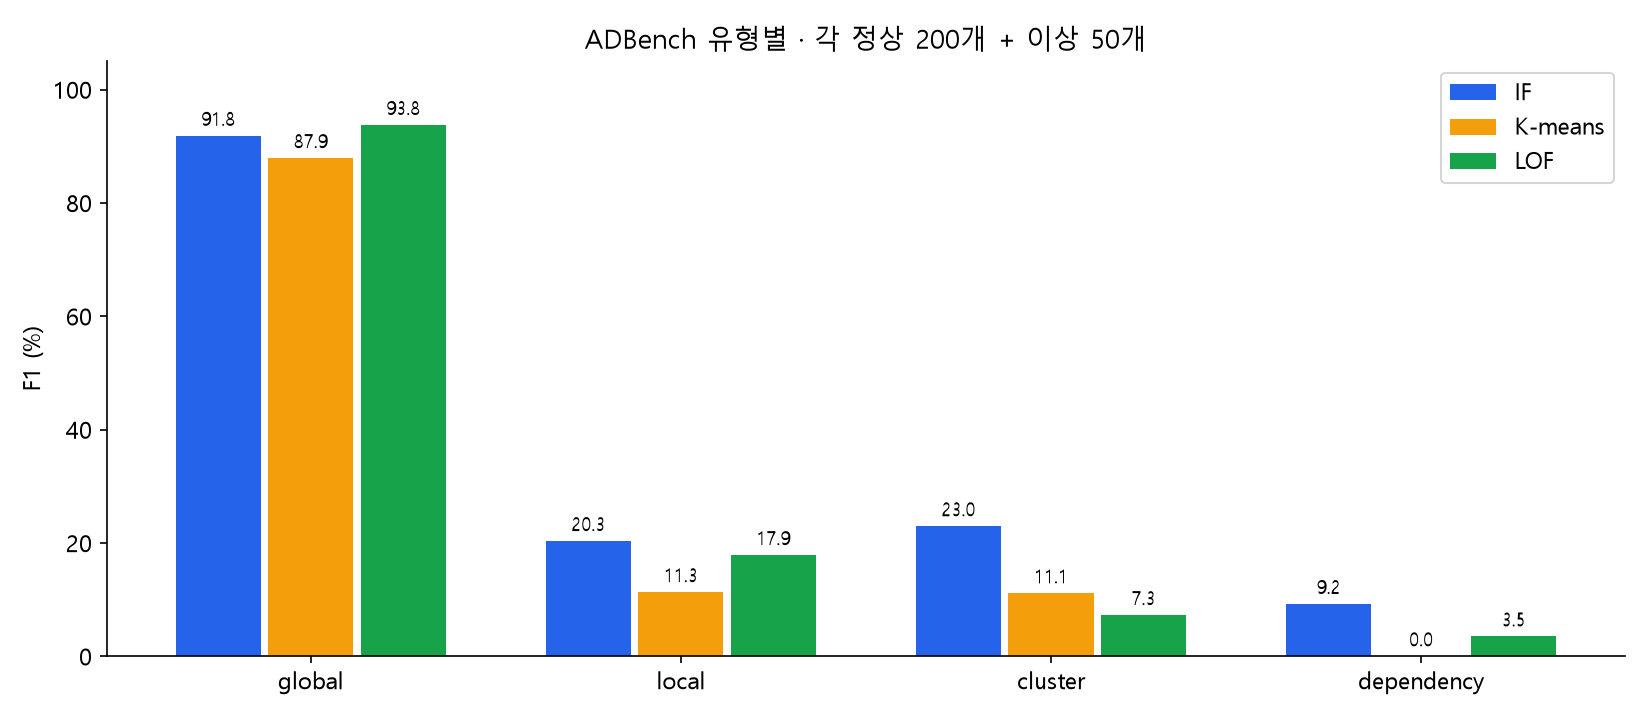

### if / ADBench 유형별

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
global,96.8,93.75,90.0,91.84,1.5
local,81.2,66.67,12.0,20.34,1.5
cluster,81.2,63.64,14.0,22.95,2.0
dependency,76.4,20.00,6.0,9.23,6.0


### kmeans / ADBench 유형별

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
global,95.6,97.56,80.0,87.91,0.5
local,81.2,100.00,6.0,11.32,0.0
cluster,80.8,75.00,6.0,11.11,0.5
dependency,78.4,0.00,0.0,0.00,2.0


### lof / ADBench 유형별

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
global,97.6,97.83,90.0,93.75,0.5
local,81.6,83.33,10.0,17.86,0.5
cluster,79.6,40.00,4.0,7.27,1.5
dependency,78.0,14.29,2.0,3.51,3.0


In [7]:
ad=read(OUT/'adbench_results.json')
for version in ['previous','improved']:
    display(Markdown('### '+version));display(metrics([r for r in ad['results']if r['version']==version]))
display(Image(filename=str(OUT/'figures/adbench.png')))
display(Image(filename=str(OUT/'figures/adbench_types.png')))
for a in ['if','kmeans','lof']:
    r=next(r for r in ad['results']if r['version']=='improved'and r['method']==a)
    display(Markdown('### '+a+' / ADBench 유형별'))
    display(metrics([{'method':m,**v}for m,v in r['types'].items()]))

**ADBench 해석:** 원시 Process 로그가 아니라 독립된 **숫자 피처 공간 평가**다. 시간 순서·입력 중단·점진적 악화를 생성한 것이 아니다. 현재 SQL/STATUS 하드 룰 검증도 적용 대상이 아니다. 생성기의 정상 레이블이 물리적으로 가능한 운영 정상 로그를 보장하지 않는다. 정상/이상 분포도 겹친다.

로그 시나리오에서 F1이 55%를 넘었다고 ADBench 모든 유형에서 높아야 하는 것은 아니다. 같은 경보선을 고정했으므로 새 분포에서 Recall이 낮아질 수 있다. global과 local/dependency 결과를 따로 본다. 1,000개 소규모 결과를 공개 ADBench 전체 순위나 실제 운영 성능으로 해석하지 않는다.

## 8. 백엔드 연결 및 재현 범위

`handoff/`에 알고리즘별 학습 모델을 저장했다. 저장·재로딩, Process 원자료→피처→점수, 새 Adapter의 전체 통계 fallback, 미래가 과거 예측에 영향을 주지 않는지 점검한다.

실시간 연결에는 Adapter+Process별 과거 상태와 연속 1분 grid, 정상 역사 집계 및 완료 로그가 필요하다. 로그가 없는 분도 만들어야 입력 중단을 탐지한다. 원시 한 행만 보내면 모든 시간 피처가 자동 계산되는 구조는 아니다. 상태 보관 워커·지연 도착 처리·운영 배포는 별도이며 이번에 GitHub/Notion/운영 모델을 자동 변경하지 않았다.

참고: [ADBench 공식 저장소](https://github.com/Minqi824/ADBench), [NeurIPS 2022 논문](https://arxiv.org/abs/2206.09426), [MiniBatch K-means](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html), [LOF](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html).